# Dry Bean Variety Classification — ML Assignment 2
**Programme:** M.Tech (Data Science & Engineering) · Machine Learning

This notebook walks through the full experiment: data loading, exploratory analysis,
preprocessing, hyper-parameter tuning and evaluation of five classifiers
(Logistic Regression, Decision Tree, kNN, Gaussian Naive Bayes, SVM).
The same functions are used by `train_models.py`, so the numbers here match the
README and the Streamlit app.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import train_models as tm          # shared configuration + model definitions
sns.set_theme(style="whitegrid")
print("Random seed:", tm.SEED, "| test fraction:", tm.TEST_FRACTION)

Random seed: 2611 | test fraction: 0.2


## 1. Load and inspect the data

In [2]:
raw = pd.read_csv(tm.DATA_FILE)
print("Shape:", raw.shape)
print("Missing values:", int(raw.isna().sum().sum()), "| exact duplicate rows:", int(raw.duplicated().sum()))
raw.head()

Shape: (13611, 17)
Missing values: 0 | exact duplicate rows: 68


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [3]:
raw.describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.2845,29324.0957,20420.0000,36328.0000,44652.0000,61332.0000,254616.0000
Perimeter,13611.0,855.2835,214.2897,524.7360,703.5235,794.9410,977.2130,1985.3700
MajorAxisLength,13611.0,320.1419,85.6942,183.6012,253.3036,296.8834,376.4950,738.8602
MinorAxisLength,13611.0,202.2707,44.9701,122.5127,175.8482,192.4317,217.0317,460.1985
AspectRation,13611.0,1.5832,0.2467,1.0249,1.4323,1.5511,1.7071,2.4303
Eccentricity,13611.0,0.7509,0.0920,0.2190,0.7159,0.7644,0.8105,0.9114
ConvexArea,13611.0,53768.2002,29774.9158,20684.0000,36714.5000,45178.0000,62294.0000,263261.0000
EquivDiameter,13611.0,253.0642,59.1771,161.2438,215.0680,238.4380,279.4465,569.3744
Extent,13611.0,0.7497,0.0491,0.5553,0.7186,0.7599,0.7869,0.8662
Solidity,13611.0,0.9871,0.0047,0.9192,0.9857,0.9883,0.9900,0.9947


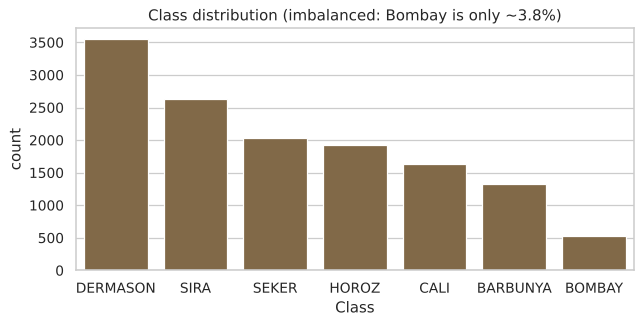

Class
DERMASON    0.261
SIRA        0.194
SEKER       0.149
HOROZ       0.142
CALI        0.120
BARBUNYA    0.097
BOMBAY      0.038
Name: count, dtype: float64

In [4]:
counts = raw["Class"].value_counts()
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.barplot(x=counts.index, y=counts.values, color="#8B6B3E", ax=ax)
ax.set_title("Class distribution (imbalanced: Bombay is only ~3.8%)"); ax.set_ylabel("count")
plt.show()
(counts / counts.sum()).round(3)

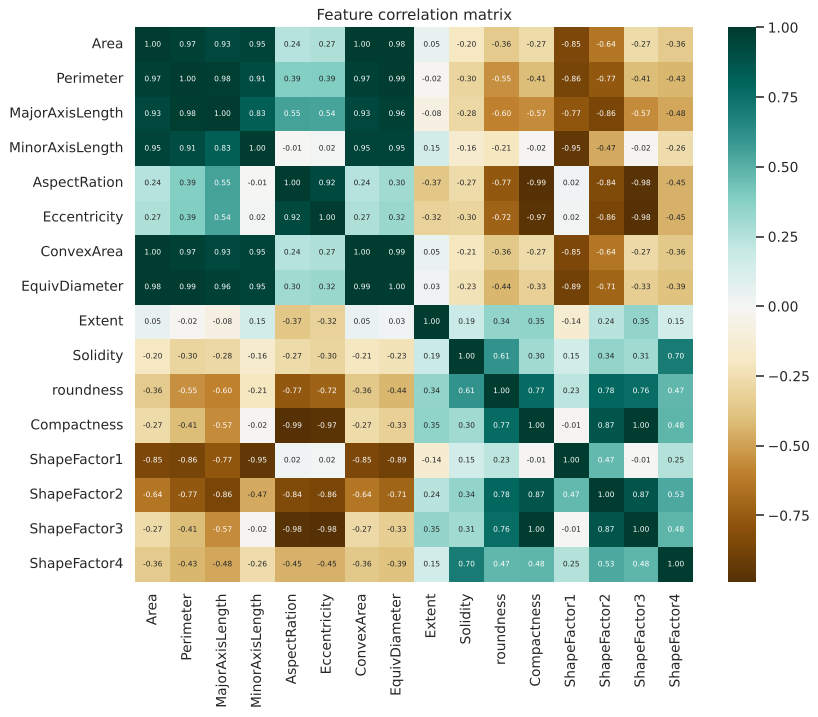

In [5]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(raw[tm.FEATURES].corr(), cmap="BrBG", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 6}, ax=ax)
ax.set_title("Feature correlation matrix")
plt.show()

**Observations.** Several size features (Area, ConvexArea, Perimeter, EquivDiameter,
axis lengths) are almost perfectly correlated (r > 0.95), and the features live on very
different scales (Area ≈ 10⁴–10⁵ vs. ShapeFactor2 ≈ 10⁻³). This motivates feature
scaling for distance/margin based models (kNN, SVM, LR) and a power transform for
Gaussian Naive Bayes, whose independence assumption is clearly violated.

## 2. Pre-processing and train/test split

In [6]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
df = tm.load_and_clean()
enc = LabelEncoder().fit(df["Class"]); y = enc.transform(df["Class"]); X = df[tm.FEATURES]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=tm.TEST_FRACTION,
                                                    stratify=y, random_state=tm.SEED)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Classes:", dict(enumerate(enc.classes_)))

Loaded 13611 rows -> 13543 after dropping duplicates
Missing values: 0
Train: (10834, 16)  Test: (2709, 16)
Classes: {0: 'BARBUNYA', 1: 'BOMBAY', 2: 'CALI', 3: 'DERMASON', 4: 'HOROZ', 5: 'SEKER', 6: 'SIRA'}


## 3. Hyper-parameter tuning (5-fold stratified CV, macro-F1) and test evaluation

In [7]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=tm.SEED)
fitted, rows = {}, []
for key, (pipe, grid) in tm.model_search_spaces().items():
    gs = GridSearchCV(pipe, grid, scoring="f1_macro", cv=cv, n_jobs=-1).fit(X_train, y_train)
    m = gs.best_estimator_; fitted[key] = m
    s = tm.evaluate(y_test, m.predict(X_test), m.predict_proba(X_test), len(enc.classes_))
    rows.append({"ML Model Name": tm.MODEL_NAMES[key], **s})
    print(f"{tm.MODEL_NAMES[key]:<24} best params: {gs.best_params_}")
results = pd.DataFrame(rows).set_index("ML Model Name").round(4)
results

Logistic Regression      best params: {'clf__C': 1.0}
Decision Tree            best params: {'clf__criterion': 'entropy', 'clf__max_depth': 10, 'clf__min_samples_leaf': 10}
kNN                      best params: {'clf__n_neighbors': 9, 'clf__weights': 'distance'}
Naive Bayes              best params: {'clf__var_smoothing': 0.001}
Support Vector Machine   best params: {'clf__estimator__C': 10, 'clf__estimator__gamma': 0.1}


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9276,0.9945,0.9394,0.9363,0.9377,0.9125
Decision Tree,0.9081,0.9817,0.9260,0.9191,0.9223,0.8887
kNN,0.9288,0.9889,0.9421,0.9377,0.9396,0.9138
Naive Bayes,0.8955,0.9918,0.9071,0.9048,0.9049,0.8742
Support Vector Machine,0.9358,0.9924,0.9484,0.9443,0.9462,0.9223


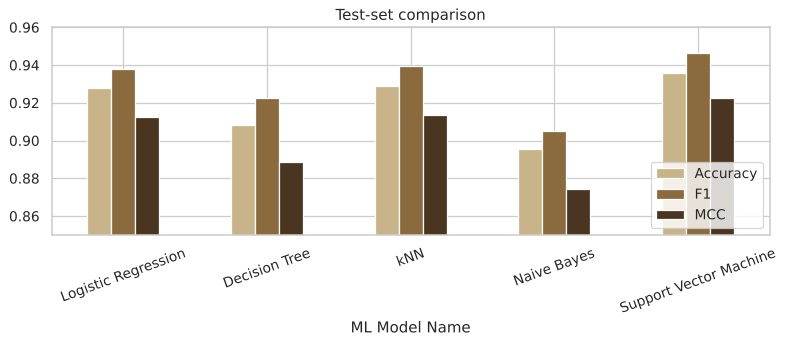

In [8]:
ax = results[["Accuracy", "F1", "MCC"]].plot.bar(figsize=(9, 4), color=["#C9B48A", "#8B6B3E", "#4A3520"])
ax.set_ylim(0.85, 0.96); ax.set_title("Test-set comparison"); plt.xticks(rotation=20); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 4. Confusion matrices

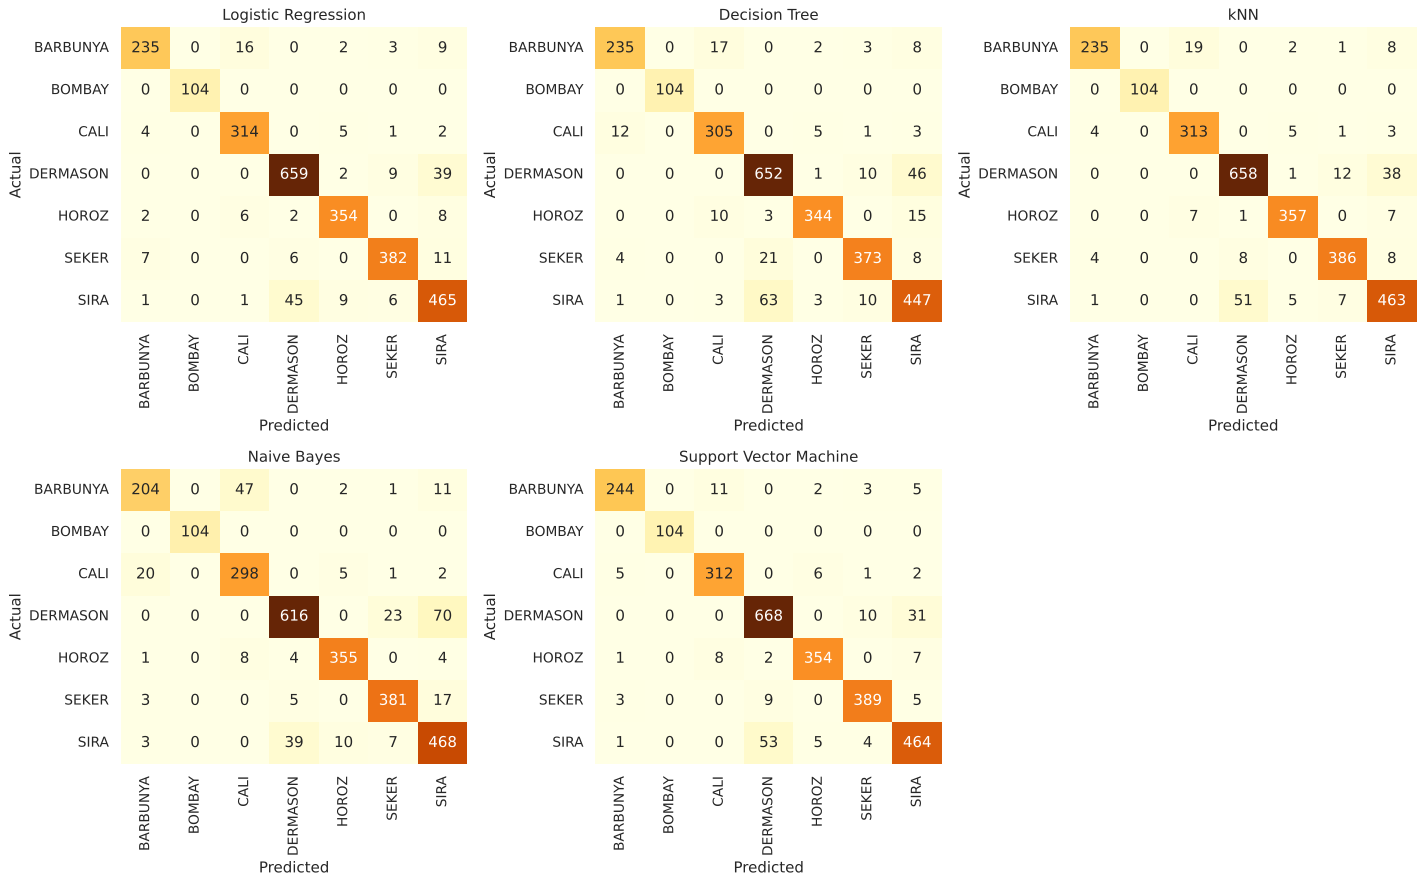

In [9]:
from sklearn.metrics import confusion_matrix
fig, axes = plt.subplots(2, 3, figsize=(16, 10)); axes = axes.ravel()
for ax, (key, m) in zip(axes, fitted.items()):
    cm = confusion_matrix(y_test, m.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="YlOrBr", cbar=False, ax=ax,
                xticklabels=enc.classes_, yticklabels=enc.classes_)
    ax.set_title(tm.MODEL_NAMES[key]); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
axes[-1].axis("off"); plt.tight_layout(); plt.show()

In [10]:
from sklearn.metrics import classification_report
print(classification_report(y_test, fitted["svm"].predict(X_test), target_names=enc.classes_, digits=4))

              precision    recall  f1-score   support

    BARBUNYA     0.9606    0.9208    0.9403       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9426    0.9571    0.9498       326
    DERMASON     0.9126    0.9422    0.9271       709
       HOROZ     0.9646    0.9516    0.9581       372
       SEKER     0.9558    0.9581    0.9569       406
        SIRA     0.9027    0.8805    0.8915       527

    accuracy                         0.9358      2709
   macro avg     0.9484    0.9443    0.9462      2709
weighted avg     0.9359    0.9358    0.9357      2709



## 5. Conclusion
* **SVM (RBF)** is the best model overall (highest Accuracy, F1 and MCC).
* kNN and Logistic Regression are close behind; LR has the best AUC (best-ranked probabilities).
* Decision Tree and Gaussian NB trail — the tree overfits axis-aligned splits and NB is
  hurt by strongly correlated features.
* For every model the dominant error is **SIRA ↔ DERMASON**, followed by **BARBUNYA ↔ CALI**;
  **BOMBAY** (the largest bean) is classified perfectly by all five.

Models are saved by `train_models.py` into this folder and loaded by `app.py`.